# Figure 1: Observed retirement-age distributions

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from lifelines import KaplanMeierFitter
from matplotlib.gridspec import GridSpec

In [2]:
# ---
# Load data
# ---

df = pd.read_excel(
    "data/combined_dataset.xlsx",
    sheet_name="Dataset"
)


In [3]:
# ---
# Filter data
# ---

# Remove records with non-positive lifespans
df = df[df["Lifespan"] > 0]

# Retain retired assets
df = df[df["Event"].isin([1])]

In [ ]:
# ---
# Configuration
# ---

technology_col = "Technology"
capacity_col = "Capacity (MW)"
lifespan_col = "Lifespan"
event_col = "Event"


# ---
# Technology groups
# ---

tech_groups = {
    "Fossil fuels": [
        "Coal",
        "Natural Gas",
        "Oil",
    ],
    "Core transition technologies": [
        "Solar PV",
        "Wind Onshore",
        "Wind Offshore",
        "Nuclear",
    ],
    "Other low-carbon technologies": [
        "Bioenergy",
        "Geothermal",
        "Hydropower",
        "Solar Thermal",
    ],
}


In [ ]:
# ---
# Prepare data
# ---

df_km = df.copy()

df_km[lifespan_col] = pd.to_numeric(
    df_km[lifespan_col],
    errors="coerce",
)

df_km[event_col] = pd.to_numeric(
    df_km[event_col],
    errors="coerce",
)

df_km[capacity_col] = pd.to_numeric(
    df_km[capacity_col],
    errors="coerce",
)

df_km = df_km.dropna(
    subset=[
        technology_col,
        lifespan_col,
        event_col,
    ]
).copy()

df_km = df_km[
    df_km[lifespan_col] >= 0
].copy()

In [ ]:
# ---
# Style
# ---

# Minimum font size: 10 pt
FONT_MIN = 10.0
FONT_BASE = 10.0
FONT_TICKS = 10.0
FONT_TITLE = 10.5
FONT_PANEL = 10.5
FONT_GROUP_HEADER = 11.0
FONT_REFERENCE_LABEL = 10.0
FONT_INFO = 10.0
FONT_AXIS_LABEL = 11.5

plt.rcParams.update(
    {
        "font.family": "Arial",
        "font.size": FONT_BASE,
        "axes.linewidth": 0.75,
        "axes.labelsize": FONT_AXIS_LABEL,
        "axes.titlesize": FONT_TITLE,
        "xtick.labelsize": FONT_TICKS,
        "ytick.labelsize": FONT_TICKS,
        "legend.fontsize": FONT_MIN,
        "pdf.fonttype": 42,
        "ps.fonttype": 42,
        "savefig.dpi": 600,
    }
)


# ---
# Palette
# ---

KM_COLOUR = "#222222"
CI_COLOUR = "#D9D9D9"
REFERENCE_COLOUR = "#3F708F"
GRID_COLOUR = "#BFBFBF"
SECONDARY_TEXT_COLOUR = "#555555"
TEXT_COLOUR = "#222222"
AXIS_COLOUR = "#444444"
GROUP_LINE_COLOUR = "#777777"

In [ ]:
# ---
# Calculate KM median for ordering
# ---

# Calculate the Kaplan-Meier median lifespan for one technology.
def get_km_median(tech):
    subset = df_km[
        df_km[technology_col] == tech
    ]

    if subset.empty:
        return np.nan

    km_temp = KaplanMeierFitter()

    km_temp.fit(
        durations=subset[lifespan_col],
        event_observed=subset[event_col],
    )

    return km_temp.median_survival_time_


# ---
# Order technologies within each group
# ---

# Order from older to younger according to the KM median.
ordered_groups = {}

for group_name, group_techs in tech_groups.items():
    available_techs = [
        tech
        for tech in group_techs
        if tech in df_km[technology_col].unique()
    ]

    medians = {
        tech: get_km_median(tech)
        for tech in available_techs
    }

    # Median not reached is represented by a non-finite value.
    ordered = sorted(
        available_techs,
        key=lambda tech: (
            medians[tech]
            if pd.notna(medians[tech])
            else -np.inf
        ),
        reverse=True,
    )

    ordered_groups[group_name] = ordered

# ---
# Group header
# ---

# Add a group title and horizontal separator.
def add_group_header(ax, title):
    ax.axis("off")

    ax.text(
        0.0,
        0.65,
        title,
        transform=ax.transAxes,
        ha="left",
        va="center",
        fontsize=FONT_GROUP_HEADER,
        fontweight="bold",
        color=TEXT_COLOUR,
    )

    ax.plot(
        [0.0, 1.0],
        [0.15, 0.15],
        transform=ax.transAxes,
        color=GROUP_LINE_COLOUR,
        linewidth=0.75,
        clip_on=False,
    )


# ---
# Plot one technology
# ---

# Plot one Kaplan-Meier survival panel.
def plot_km_panel(
    ax,
    tech,
    panel_label,
):
    subset = df_km[
        df_km[technology_col] == tech
    ].copy()

    if subset.empty:
        ax.axis("off")
        return

    # Fit Kaplan-Meier estimator
    km = KaplanMeierFitter()

    km.fit(
        durations=subset[lifespan_col],
        event_observed=subset[event_col],
    )

    # Extract survival curve directly from lifelines
    times = (
        km.survival_function_
        .index
        .to_numpy(dtype=float)
    )

    survival = (
        km.survival_function_
        .iloc[:, 0]
        .to_numpy(dtype=float)
    )

    # Confidence interval
    ci_times = (
        km.confidence_interval_
        .index
        .to_numpy(dtype=float)
    )

    ci_lower = (
        km.confidence_interval_
        .iloc[:, 0]
        .to_numpy(dtype=float)
    )

    ci_upper = (
        km.confidence_interval_
        .iloc[:, 1]
        .to_numpy(dtype=float)
    )

    # 95% confidence interval
    ax.fill_between(
        ci_times,
        ci_lower,
        ci_upper,
        color=CI_COLOUR,
        alpha=0.50,
        step="post",
        linewidth=0,
        zorder=1,
    )

    # KM survival curve
    ax.step(
        times,
        survival,
        where="post",
        color=KM_COLOUR,
        linewidth=1.45,
        zorder=4,
    )

    # 80%, 50%, and 10% reference levels
    for level in [
        0.8,
        0.5,
        0.1,
    ]:
        crossed = np.where(
            survival <= level
        )[0]

        if len(crossed) == 0:
            continue

        idx = crossed[0]
        t_level = times[idx]

        # Give the median slightly stronger visual weight
        is_median = level == 0.5
        line_alpha = 0.95 if is_median else 0.60
        line_width = 1.00 if is_median else 0.80
        text_alpha = 1.00 if is_median else 0.80

        # Horizontal reference line
        ax.hlines(
            y=level,
            xmin=0,
            xmax=t_level,
            color=REFERENCE_COLOUR,
            linestyle="--",
            linewidth=line_width,
            alpha=line_alpha,
            zorder=2,
        )

        # Vertical reference line
        ax.vlines(
            x=t_level,
            ymin=0,
            ymax=level,
            color=REFERENCE_COLOUR,
            linestyle="--",
            linewidth=line_width,
            alpha=line_alpha,
            zorder=2,
        )

        # Age label
        ax.text(
            t_level + 1.5,
            level + 0.018,
            f"{t_level:.0f} y",
            ha="left",
            va="bottom",
            fontsize=FONT_REFERENCE_LABEL,
            fontweight=(
                "bold"
                if is_median
                else "normal"
            ),
            color=REFERENCE_COLOUR,
            alpha=text_alpha,
            zorder=5,
        )

    # Number of units and installed capacity
    n_units = len(subset)

    total_cap_gw = (
        subset[capacity_col]
        .sum()
        / 1000
    )

    ax.text(
        0.97,
        0.95,
        (
            f"n = {n_units:,} | "
            f"{total_cap_gw:.2f} GW"
        ),
        transform=ax.transAxes,
        ha="right",
        va="top",
        fontsize=FONT_INFO,
        color=SECONDARY_TEXT_COLOUR,
    )

    # Panel label
    ax.text(
        -0.13,
        1.12,
        panel_label,
        transform=ax.transAxes,
        ha="left",
        va="top",
        fontsize=FONT_PANEL,
        fontweight="bold",
        color=TEXT_COLOUR,
    )

    # Title
    ax.set_title(
        tech,
        fontsize=FONT_TITLE,
        fontweight="bold",
        pad=6,
        color=TEXT_COLOUR,
    )

    # Axes
    ax.set_xlim(
        0,
        125,
    )

    ax.set_ylim(
        0,
        1.02,
    )

    ax.set_xticks(
        np.arange(
            0,
            126,
            25,
        )
    )

    ax.set_yticks(
        [
            0,
            0.1,
            0.5,
            0.8,
            1.0,
        ]
    )

    # Grid
    ax.grid(
        axis="y",
        linestyle="-",
        linewidth=0.45,
        alpha=0.30,
        color=GRID_COLOUR,
        zorder=0,
    )

    # Spines
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

    ax.spines["left"].set_linewidth(0.75)
    ax.spines["bottom"].set_linewidth(0.75)

    ax.spines["left"].set_color(AXIS_COLOUR)
    ax.spines["bottom"].set_color(AXIS_COLOUR)

    # Ticks
    ax.tick_params(
        axis="both",
        direction="out",
        length=3.2,
        width=0.75,
        pad=3,
        labelbottom=True,
        labelleft=True,
        labelsize=FONT_TICKS,
        colors=TEXT_COLOUR,
    )


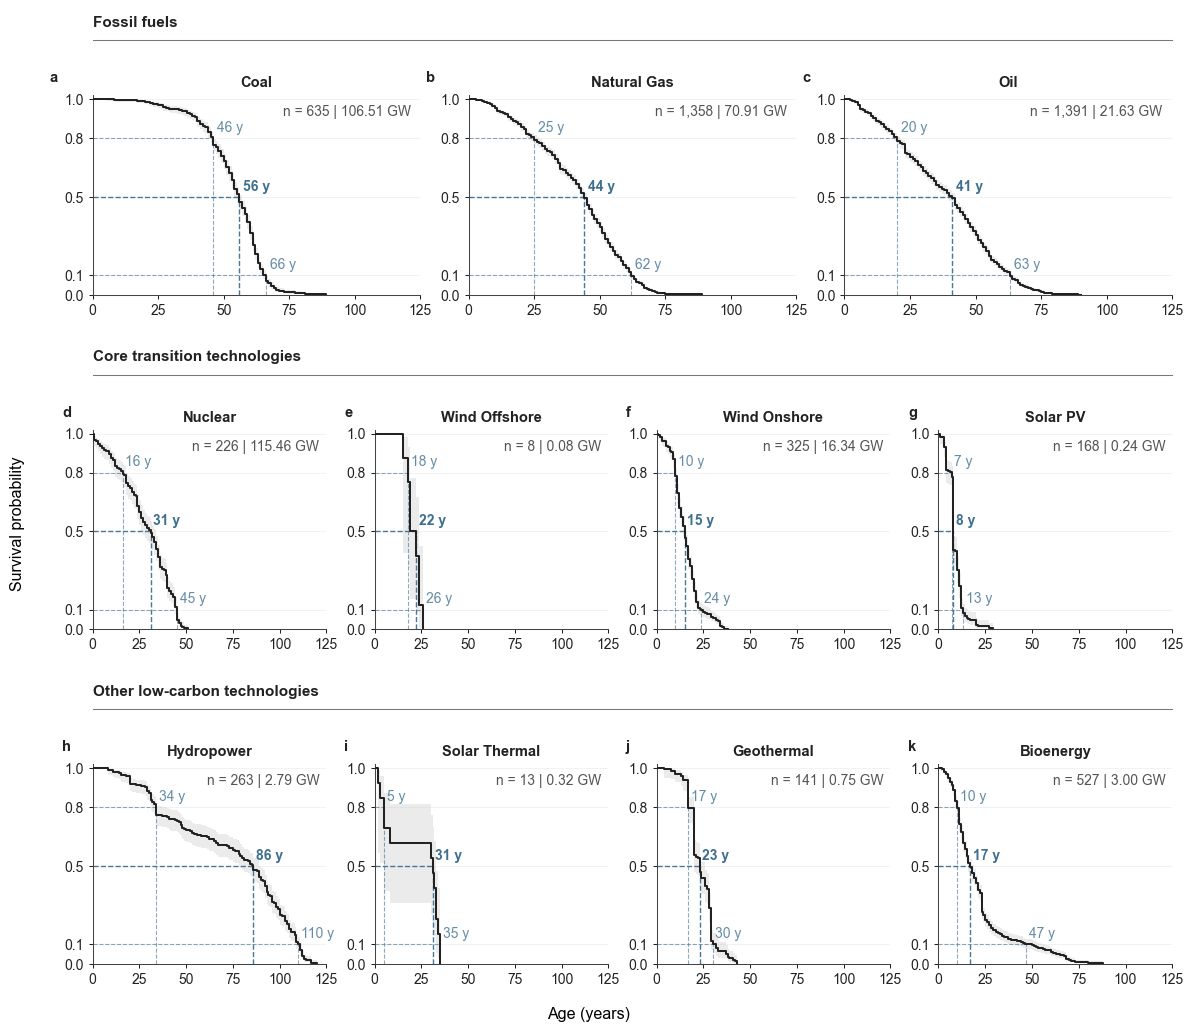

In [4]:
# ---
# Figure
# ---

fig = plt.figure(
    figsize=(11.8, 10.6),
)

gs = GridSpec(
    nrows=6,
    ncols=12,
    figure=fig,
    height_ratios=[
        0.18,
        1.0,
        0.18,
        1.0,
        0.18,
        1.0,
    ],
    hspace=0.42,
    wspace=1.05,
)


# ---
# Group headers
# ---

group_names = list(
    ordered_groups.keys()
)

header_axes = [
    fig.add_subplot(
        gs[0, :],
    ),
    fig.add_subplot(
        gs[2, :],
    ),
    fig.add_subplot(
        gs[4, :],
    ),
]

for ax_header, group_name in zip(
    header_axes,
    group_names,
):
    add_group_header(
        ax_header,
        group_name,
    )


# ---
# Panel positions
# ---

# Fossil fuels
fossil_positions = [
    (1, slice(0, 4)),
    (1, slice(4, 8)),
    (1, slice(8, 12)),
]

# Core transition technologies
transition_positions = [
    (3, slice(0, 3)),
    (3, slice(3, 6)),
    (3, slice(6, 9)),
    (3, slice(9, 12)),
]

# Other low-carbon technologies
other_positions = [
    (5, slice(0, 3)),
    (5, slice(3, 6)),
    (5, slice(6, 9)),
    (5, slice(9, 12)),
]

group_positions = {
    group_names[0]: fossil_positions,
    group_names[1]: transition_positions,
    group_names[2]: other_positions,
}


# ---
# Create panels
# ---

share_ax = None
panel_counter = 0

for group_name in group_names:
    tech_list = ordered_groups[group_name]
    positions = group_positions[group_name]

    for tech, (row_i, col_slice) in zip(
        tech_list,
        positions,
    ):
        if share_ax is None:
            ax = fig.add_subplot(
                gs[row_i, col_slice],
            )
            share_ax = ax

        else:
            ax = fig.add_subplot(
                gs[row_i, col_slice],
                sharex=share_ax,
                sharey=share_ax,
            )

        plot_km_panel(
            ax=ax,
            tech=tech,
            panel_label=chr(
                97 + panel_counter
            ),
        )

        panel_counter += 1


# ---
# Global labels
# ---

fig.supylabel(
    "Survival probability",
    fontsize=FONT_AXIS_LABEL,
    fontweight="normal",
    x=0.010,
)

fig.supxlabel(
    "Age (years)",
    fontsize=FONT_AXIS_LABEL,
    fontweight="normal",
    y=0.030,
)


# ---
# Layout
# ---

fig.subplots_adjust(
    left=0.080,
    right=0.995,
    bottom=0.085,
    top=0.985,
)


# ---
# Save
# ---
plt.savefig(
    "figures/main/figure-1.png",
    dpi=600,
    bbox_inches="tight",
    transparent=True,
)

plt.savefig(
    "figures/main/figure-1.pdf",
    bbox_inches="tight",
    transparent=True,
)

plt.show()
